<a href="https://colab.research.google.com/github/ShesaaVarshniMM/text_classifier_comparison_IRAssignment_RA2411026050031/blob/main/Text_Classification_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd

df = pd.read_csv("/spam.csv", encoding="latin-1")

print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())


     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  

Dataset shape: (5572, 5)

Column names: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [4]:

# Keep only the two required columns
df = df[["v1", "v2"]].copy()

# Rename them
df.columns = ["label", "message"]

# Check the result
print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())



  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


In [5]:

# Remove rows with missing labels or messages, if any
df = df.dropna(subset=["label", "message"]).copy()

# Make sure labels and messages are strings
df["label"] = df["label"].astype(str).str.strip()
df["message"] = df["message"].astype(str)

# Keep only the two expected classes
df = df[df["label"].isin(["ham", "spam"])].copy()

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df[["label", "message"]].isnull().sum())


Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


In [6]:

from sklearn.model_selection import train_test_split

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))


Training messages: 4457
Testing messages: 1115

Training class distribution:
label
ham     3859
spam     598
Name: count, dtype: int64

Testing class distribution:
label
ham     966
spam    149
Name: count, dtype: int64
Training TF-IDF shape: (4457, 7440)
Testing TF-IDF shape: (1115, 7440)
Vocabulary size: 7440


In [7]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),
    "Naive Bayes": MultinomialNB()
}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print(name, "trained successfully")


Decision Tree trained successfully
KNN trained successfully
SVM trained successfully
Naive Bayes trained successfully


In [8]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            pos_label="spam", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred,
            pos_label="spam", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


    Algorithm  Accuracy  Precision  Recall  F1-score
Decision Tree    0.9596     0.8714  0.8188    0.8443
          KNN    0.9121     1.0000  0.3423    0.5100
          SVM    0.9839     0.9925  0.8859    0.9362
  Naive Bayes    0.9686     1.0000  0.7651    0.8669


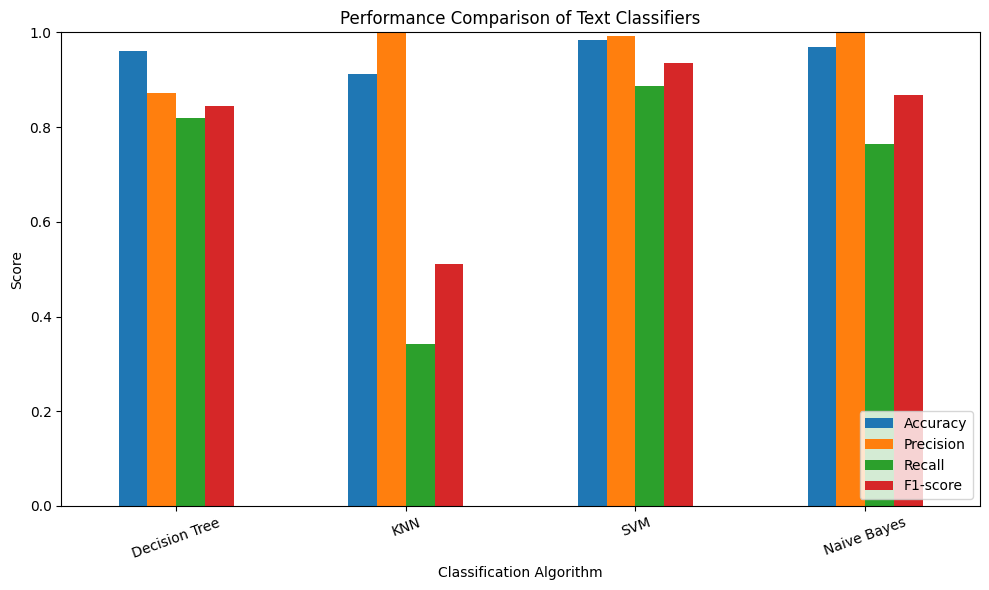

In [9]:

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Performance Comparison of Text Classifiers")
plt.xlabel("Classification Algorithm")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()



Confusion Matrix: Decision Tree
[[948  18]
 [ 27 122]]


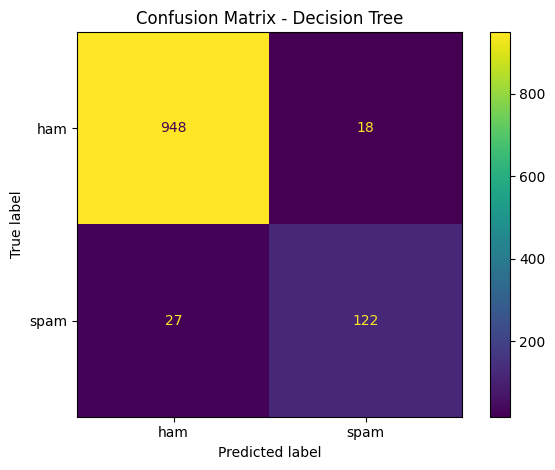


Confusion Matrix: KNN
[[966   0]
 [ 98  51]]


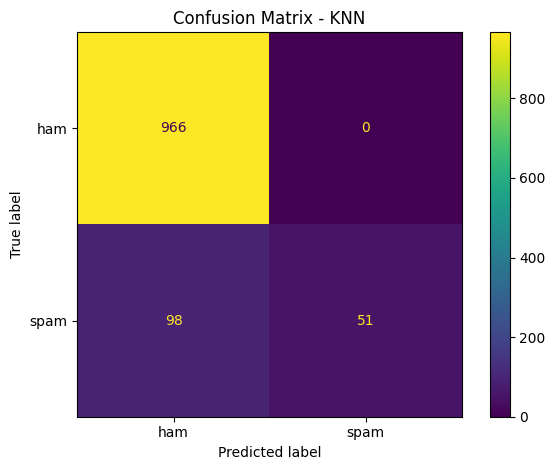


Confusion Matrix: SVM
[[965   1]
 [ 17 132]]


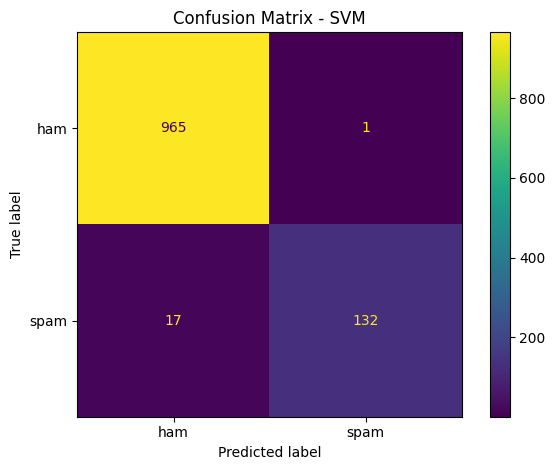


Confusion Matrix: Naive Bayes
[[966   0]
 [ 35 114]]


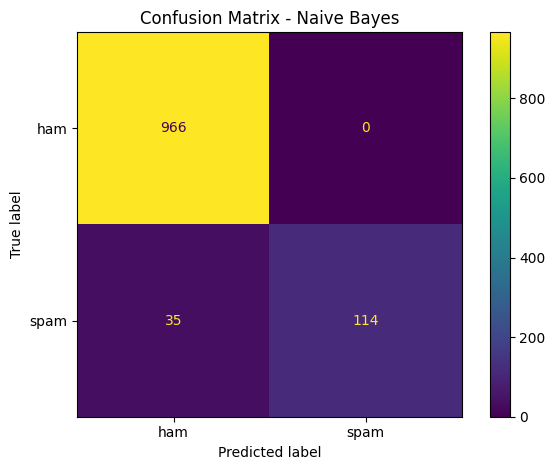

In [10]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    print(f"\nConfusion Matrix: {name}")
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["ham", "spam"]
    )

    disp.plot()
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


In [12]:

svm_what_if = LinearSVC(
    C=0.1,
    random_state=42,
    max_iter=5000
)

svm_what_if.fit(X_train_tfidf, y_train)

what_if_pred = svm_what_if.predict(X_test_tfidf)

print("Modified SVM trained successfully.")

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline_svm = results_df[
    results_df["Algorithm"] == "SVM"
][["Accuracy", "Precision", "Recall", "F1-score"]].iloc[0]

modified_svm = pd.Series({
    "Accuracy": accuracy_score(y_test, what_if_pred),
    "Precision": precision_score(
        y_test, what_if_pred,
        pos_label="spam", zero_division=0
    ),
    "Recall": recall_score(
        y_test, what_if_pred,
        pos_label="spam", zero_division=0
    ),
    "F1-score": f1_score(
        y_test, what_if_pred,
        pos_label="spam", zero_division=0
    )
})

comparison = pd.DataFrame(
    [baseline_svm, modified_svm],
    index=["Baseline SVM (C=1.0)", "Modified SVM (C=0.1)"]
)

print(comparison.round(4))
print("\nChange in scores (modified - baseline):")
print((modified_svm - baseline_svm).round(4))



Modified SVM trained successfully.
                      Accuracy  Precision  Recall  F1-score
Baseline SVM (C=1.0)    0.9839     0.9925  0.8859    0.9362
Modified SVM (C=0.1)    0.9731     0.9917  0.8054    0.8889

Change in scores (modified - baseline):
Accuracy    -0.0108
Precision   -0.0007
Recall      -0.0805
F1-score    -0.0473
dtype: float64


In [13]:

ranked_results = results_df.sort_values(
    by="F1-score",
    ascending=False
)

print(ranked_results.round(4).to_string(index=False))

best_model_name = ranked_results.iloc[0]["Algorithm"]
print("\nHighest spam F1-score:", best_model_name)


    Algorithm  Accuracy  Precision  Recall  F1-score
          SVM    0.9839     0.9925  0.8859    0.9362
  Naive Bayes    0.9686     1.0000  0.7651    0.8669
Decision Tree    0.9596     0.8714  0.8188    0.8443
          KNN    0.9121     1.0000  0.3423    0.5100

Highest spam F1-score: SVM


In [14]:

results_df.to_csv("model_comparison_results.csv", index=False)

print("Results saved to model_comparison_results.csv")


Results saved to model_comparison_results.csv
